# Figure 1

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_behavioral_data,
    DATASET_CURRENCY,
    LOSS_AVERSION,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [2]:
def _fmt_tick(v):
    try:
        return f"{float(v):g}"
    except (ValueError, TypeError):
        return str(v)


def plot_gain_loss_heatmap(ax, hmap_data, dataset, cmap, vmin, vmax, cbar_label,
                           show_loss_aversion=True):
    """Gain (rows) x loss (columns) heatmap, optionally with the gain =
    lambda * loss loss-aversion diagonal. hmap_data: index=loss, columns=gain."""
    losses = hmap_data.index.values.astype(float)
    gains  = hmap_data.columns.values.astype(float)
    hmap_t = hmap_data.T  # rows=gain, columns=loss

    sns.heatmap(
        hmap_t, cmap=cmap, square=True, linewidths=1, linecolor="black",
        vmin=vmin, vmax=vmax, cbar=True, cbar_kws={"label": cbar_label},
        ax=ax, xticklabels=True, yticklabels=True,
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(rotation=90)
    ax.invert_yaxis()  # gain increases from bottom to top

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

    if show_loss_aversion:
        lambd = LOSS_AVERSION.get(dataset)
        if lambd is not None:
            n_rows, n_cols = len(gains), len(losses)
            loss_endpoints = np.array([losses.min(), losses.max()])
            gain_endpoints = lambd * loss_endpoints
            loss_coords = (
                0.5 + (loss_endpoints - losses.min())
                / (losses.max() - losses.min()) * (n_cols - 1)
            )
            gain_coords = (
                0.5 + (gain_endpoints - gains.min())
                / (gains.max() - gains.min()) * (n_rows - 1)
            )
            ax.plot(loss_coords, gain_coords, color="black", linestyle="--", linewidth=4)

    currency = DATASET_CURRENCY.get(dataset, "")
    ax.set_xlabel(f"Loss ({currency})")
    ax.set_ylabel(f"Gain ({currency})")
    ax.set_xticklabels([_fmt_tick(v) for v in losses])
    ax.set_yticklabels([_fmt_tick(v) for v in gains])

### 2x3 figure: acceptance grids, RT grids
Columns = datasets. Row 1: acceptance rate across gain x loss. Row 2: mean RT across gain x loss.

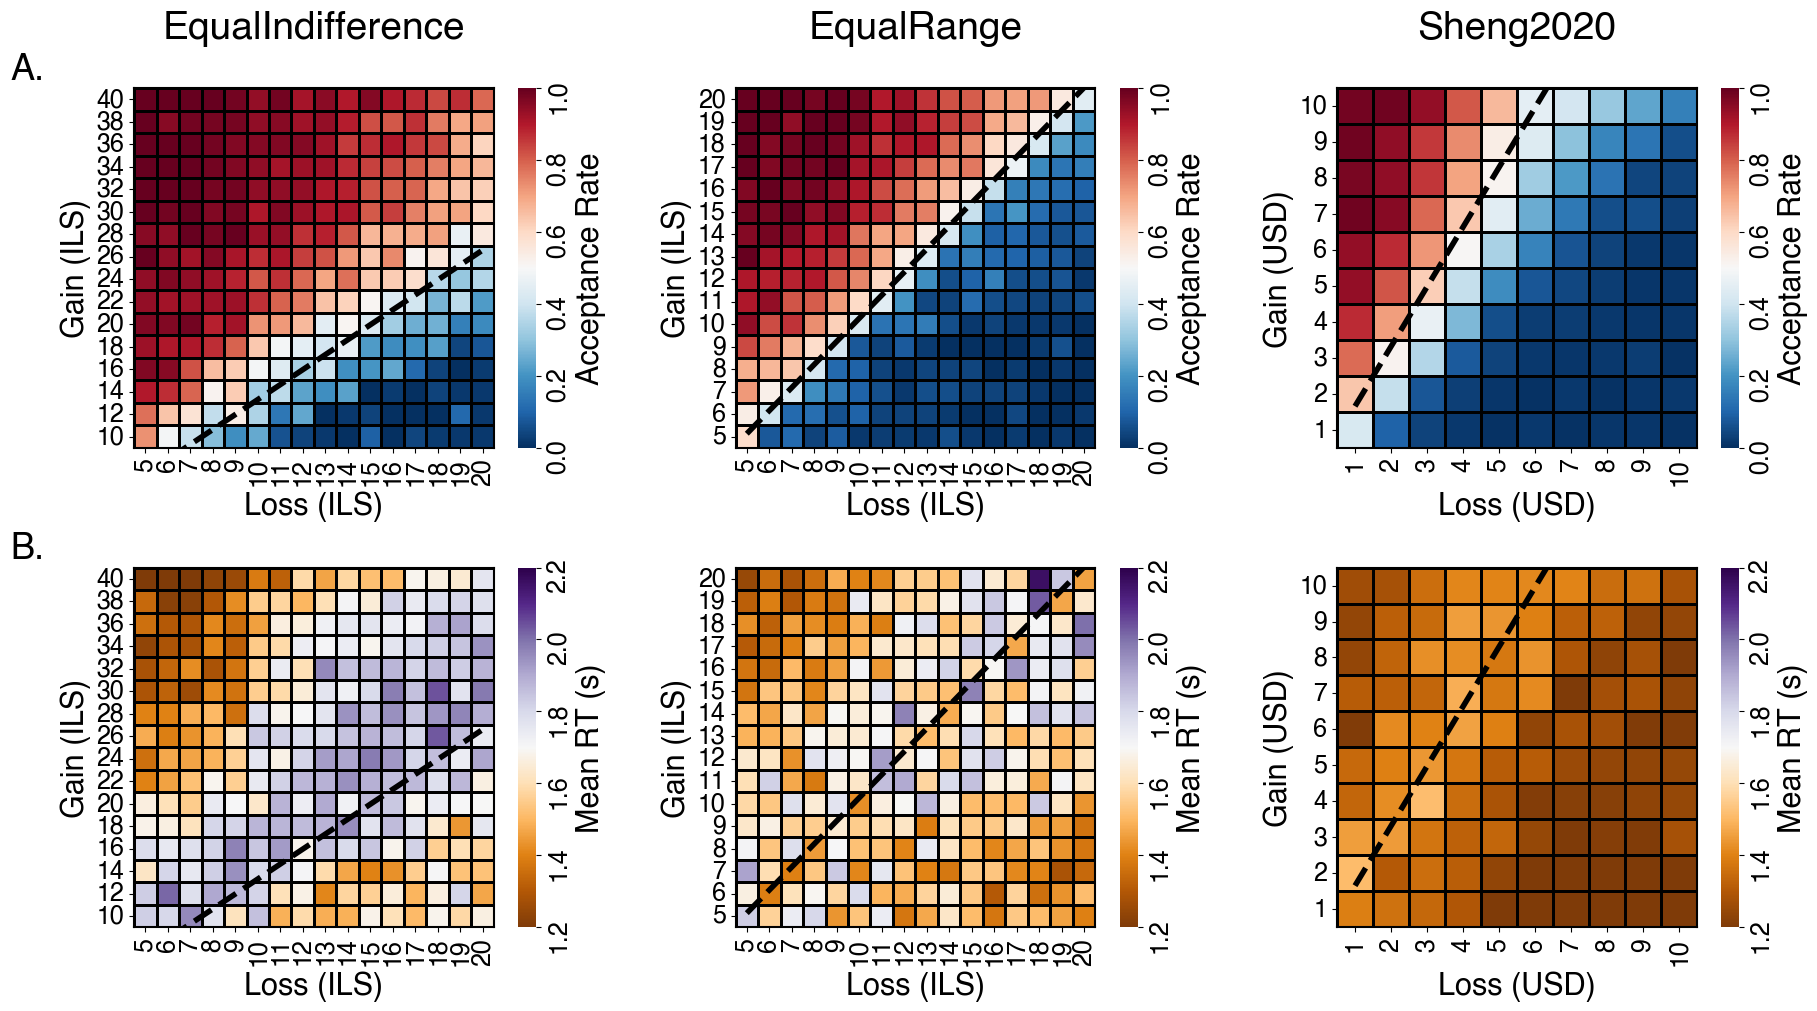

In [5]:
behavior_data = load_behavioral_data()

ACCEPT_CMAP = "RdBu_r"
RT_CMAP = "PuOr"
RT_VMIN, RT_VMAX = 1.2, 2.2  # seconds
ROW_LABELS = ["A.", "B."]

accept_hmaps = {}
rt_hmaps = {}
for ds in DATASETS:
    ds_data = behavior_data[behavior_data["dataset"] == ds]
    subj_cell_means = (
        ds_data.groupby(["sub", "loss", "gain"])[["accept", "rt"]]
        .mean()
        .reset_index()
    )
    accept_hmaps[ds] = subj_cell_means.groupby(["loss", "gain"])["accept"].mean().unstack()
    rt_hmaps[ds] = subj_cell_means.groupby(["loss", "gain"])["rt"].mean().unstack()

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10), layout="constrained")

for col, ds in enumerate(DATASETS):
    axes[0, col].set_title(f"{DATASET_LABELS.get(ds, ds)}\n", fontweight="bold")

    plot_gain_loss_heatmap(
        axes[0, col], accept_hmaps[ds], ds,
        cmap=ACCEPT_CMAP, vmin=0, vmax=1, cbar_label="Acceptance Rate",
    )

    plot_gain_loss_heatmap(
        axes[1, col], rt_hmaps[ds], ds,
        cmap=RT_CMAP, vmin=RT_VMIN, vmax=RT_VMAX, cbar_label="Mean RT (s)",
    )

# Row labels, placed just outside the top-left corner of each row's leftmost panel
for row, label in enumerate(ROW_LABELS):
    axes[row, 0].text(-0.25, 1.1, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")


fig.savefig("saved/figure1.svg", dpi=300, bbox_inches="tight")
plt.show()